# Location- and Time-Aware Raga Recommendation with Emotion Conditioning
### Solar-corrected *prahar* model — complete, self-contained Colab implementation

**Author:** Dr. Sudipta Bhattacharya · Dept. of CSE (AIML), Institute of Engineering and Management, Kolkata

This notebook implements **Section 4.2 (location-corrected prahar formulation)** of the Transactions draft end-to-end and runs the headline experiments. It needs **no external data or GPU** — just *Runtime ▸ Run all* (≈1–2 min).

| Part | Content | Paper section |
|---|---|---|
| 1–3 | Solar engine: Eqs. (1)–(6) | §4.2.1–4.2.5 |
| 4 | Validation vs. the worked-example table (Kolkata/Srinagar, Dec/Jun) | §4.2.6, Table II |
| 5 | Figures: year-round prahar clock, longitude effect | §4.2.6 |
| 6 | Unified source-cited raga knowledge base (v2) + straddling ψ-arcs | §5 |
| 7 | **Analytic result:** fixed-clock vs solar window divergence across India × seasons | §7 |
| 8–9 | Query simulation, feature variants, FFNN training, ablation | §4.3–§7 |
| 9a | Non-learned baselines: rule lookup + Bayes-optimal under the generative model | §7 |
| 9b | Uncertainty over data-generation seeds: bootstrap CIs, effect sizes, Wilcoxon | §6, §7 |
| 9c | Per-city gain from solar correction, pooled over seeds | §7 |
| 10 | `recommend_raga(lat, lon, when, emotion)` — deployment function | §8 |
| 11 | Hooks for real data (Saraga audio, SSL embeddings, psychometric labels) | §5 |

Sources: Roy, Chakrabarty & De, *IJ-AI* 6(1), 2017 (time-based raga NN) · Basu et al., *Physica A* 624, 2023 (emotion/EEG) · Aljanaki et al., *PLOS ONE* 12(3), 2017 (DEAM, MER protocol).

## 1 · Setup
Standard scientific stack + PyTorch (preinstalled in Colab). Fixed seeds for reproducibility.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from datetime import date, datetime
from dataclasses import dataclass

try:
    import torch, torch.nn as nn
except ImportError as e:
    raise SystemExit("PyTorch not found. In Colab it is preinstalled; locally run: pip install torch") from e

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SEED = 7
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

# Colorblind-safe categorical palette (fixed slot order) + single-hue sequentials
PAL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

IST_MERIDIAN = 82.5   # degrees east — reference meridian of UTC+5:30

# Indian sites used throughout (all on IST)
CITIES = pd.DataFrame(
    [("Srinagar", 34.08, 74.80), ("Amritsar", 31.63, 74.87),
     ("Delhi", 28.61, 77.21), ("Jaipur", 26.91, 75.79),
     ("Bhuj", 23.24, 69.67), ("Ahmedabad", 23.03, 72.58),
     ("Mumbai", 19.08, 72.88), ("Kolkata", 22.57, 88.36),
     ("Guwahati", 26.14, 91.74), ("Dibrugarh", 27.47, 94.91),
     ("Chennai", 13.08, 80.27), ("Bengaluru", 12.97, 77.59),
     ("Thiruvananthapuram", 8.52, 76.94)],
    columns=["city", "lat", "lon"])
CITIES.T

device: cpu


,0,1,2,3,4,5,6,7,8,9,10,11,12
city,Srinagar,Amritsar,Delhi,Jaipur,Bhuj,Ahmedabad,Mumbai,Kolkata,Guwahati,Dibrugarh,Chennai,Bengaluru,Thiruvananthapuram
lat,34.08,31.63,28.61,26.91,23.24,23.03,19.08,22.57,26.14,27.47,13.08,12.97,8.52
lon,74.8,74.87,77.21,75.79,69.67,72.58,72.88,88.36,91.74,94.91,80.27,77.59,76.94


## 2 · Solar engine — Eqs. (1)–(4)

Solar declination and equation of time for day-of-year $N$:

$$\delta(N)=23.44^{\circ}\sin\!\Big(\tfrac{360^{\circ}}{365}(N-81)\Big)\tag{1}$$

$$B=\tfrac{360^{\circ}}{365}(N-81),\qquad E(N)=9.87\sin 2B-7.53\cos B-1.5\sin B\;\;[\mathrm{min}]\tag{2}$$

Local solar time from clock time $t$ at longitude $\lambda$ (timezone meridian $\lambda_{tz}$), then day length from the sunrise hour angle $\omega_0$:

$$T_{\mathrm{sol}}=t+\frac{4(\lambda-\lambda_{tz})+E(N)}{60}\tag{3}$$

$$\cos\omega_0=-\tan\varphi\,\tan\delta,\qquad D=\frac{2\omega_0}{15^{\circ}},\qquad \bar D=24-D\tag{4}$$

Sunrise/sunset in solar time are $12\mp\omega_0/15$; invert Eq. (3) for clock time. `refraction=True` restores the standard $-0.833^{\circ}$ altitude term (≈3–4 min).

In [2]:
def solar_declination(N):
    '''Eq. (1): declination delta(N) in degrees for day-of-year N.'''
    return 23.44 * np.sin(np.radians(360.0 / 365.0 * (N - 81)))

def equation_of_time(N):
    '''Eq. (2): equation of time E(N) in minutes for day-of-year N.'''
    B = np.radians(360.0 / 365.0 * (N - 81))
    return 9.87 * np.sin(2 * B) - 7.53 * np.cos(B) - 1.5 * np.sin(B)

def clock_to_solar(t_clock, lon, N, lon_tz=IST_MERIDIAN):
    '''Eq. (3): local solar time (hours) from clock time (hours).'''
    return t_clock + (4.0 * (lon - lon_tz) + equation_of_time(N)) / 60.0

def solar_to_clock(t_solar, lon, N, lon_tz=IST_MERIDIAN):
    '''Inverse of Eq. (3).'''
    return t_solar - (4.0 * (lon - lon_tz) + equation_of_time(N)) / 60.0

def sunrise_sunset(lat, lon, N, lon_tz=IST_MERIDIAN, refraction=False):
    '''Eq. (4): (sunrise_clock, sunset_clock, D, Dbar) in local clock hours.'''
    delta = solar_declination(N)
    if refraction:
        h0 = np.radians(-0.833)   # refraction + solar semidiameter
        cos_w0 = ((np.sin(h0) - np.sin(np.radians(lat)) * np.sin(np.radians(delta)))
                  / (np.cos(np.radians(lat)) * np.cos(np.radians(delta))))
    else:
        cos_w0 = -np.tan(np.radians(lat)) * np.tan(np.radians(delta))
    cos_w0 = np.clip(cos_w0, -1.0, 1.0)          # polar-edge completeness
    w0 = np.degrees(np.arccos(cos_w0))           # sunrise hour angle, degrees
    D = 2.0 * w0 / 15.0
    Dbar = 24.0 - D
    t_sr = solar_to_clock(12.0 - w0 / 15.0, lon, N, lon_tz)
    t_ss = solar_to_clock(12.0 + w0 / 15.0, lon, N, lon_tz)
    return t_sr, t_ss, D, Dbar

def day_of_year(d):
    return d.timetuple().tm_yday if isinstance(d, (datetime, date)) else int(d)

def hhmm(h):
    '''Format decimal hours as HH:MM (wraps modulo 24).'''
    h = h % 24.0; H = int(h); M = int(round((h - H) * 60))
    if M == 60: H, M = (H + 1) % 24, 0
    return f"{H:02d}:{M:02d}"

print("engine ready — e.g. Kolkata 21 Dec sunrise:",
      hhmm(sunrise_sunset(22.57, 88.36, day_of_year(date(2026,12,21)))[0]), "IST")

engine ready — e.g. Kolkata 21 Dec sunrise: 06:17 IST


## 3 · Prahar index and solar-normalized phase — Eqs. (5)–(6)

Daylight and night are each split into four watches:

$$\Pi(t,\ell,d)=\begin{cases}\big\lceil 4(T_{\mathrm{sol}}-t_{sr})/D\big\rceil,& t_{sr}\le T_{\mathrm{sol}}<t_{ss}\;(\text{day},\;\Pi\in\{1..4\})\\[3pt]4+\big\lceil 4\Delta/\bar D\big\rceil,\;\Delta=(T_{\mathrm{sol}}-t_{ss})\bmod 24,&\text{otherwise}\;(\text{night},\;\Pi\in\{5..8\})\end{cases}\tag{5}$$

The **solar-normalized phase** $\psi\in[0,1)$ maps every day onto $[0,0.5)$ and every night onto $[0.5,1)$ — season-invariant by construction — and feeds the network as a cyclic encoding:

$$\psi=\begin{cases}\dfrac{T_{\mathrm{sol}}-t_{sr}}{2D},&\text{day}\\[6pt]\dfrac12+\dfrac{\Delta}{2\bar D},&\text{night}\end{cases}\qquad \mathbf{x}_{\mathrm{time}}=\big[\sin 2\pi\psi,\;\cos 2\pi\psi,\;\mathrm{onehot}(\Pi)\big]\tag{6}$$

In [3]:
def prahar_phase(t_clock, lat, lon, N, lon_tz=IST_MERIDIAN, refraction=False):
    '''Eq. (5)-(6): returns (Pi, psi); Pi in {1..8}, psi in [0,1).'''
    t_sr, t_ss, D, Dbar = sunrise_sunset(lat, lon, N, lon_tz, refraction)
    T    = clock_to_solar(t_clock, lon, N, lon_tz)
    T_sr = clock_to_solar(t_sr,   lon, N, lon_tz)
    T_ss = clock_to_solar(t_ss,   lon, N, lon_tz)
    if T_sr <= T < T_ss:                               # day
        frac = (T - T_sr) / D
        Pi  = min(max(int(np.ceil(4 * frac)) if frac > 0 else 1, 1), 4)
        psi = frac / 2.0
    else:                                              # night
        delta_h = (T - T_ss) % 24.0
        frac = delta_h / Dbar
        Pi  = min(max(4 + (int(np.ceil(4 * frac)) if frac > 0 else 1), 5), 8)
        psi = 0.5 + frac / 2.0
    return Pi, psi % 1.0

def time_features(t_clock, lat, lon, N, lon_tz=IST_MERIDIAN):
    '''Eq. (6): x_time = [sin 2*pi*psi, cos 2*pi*psi, onehot(Pi)]  (length 10).'''
    Pi, psi = prahar_phase(t_clock, lat, lon, N, lon_tz)
    onehot = np.zeros(8); onehot[Pi - 1] = 1.0
    return np.concatenate(([np.sin(2*np.pi*psi), np.cos(2*np.pi*psi)], onehot))

Pi, psi = prahar_phase(20.5, 22.57, 88.36, day_of_year(date(2026, 10, 11)))
print(f"Kolkata, 11 Oct, 20:30 IST  ->  prahar P{Pi}, psi = {psi:.3f}")

Kolkata, 11 Oct, 20:30 IST  ->  prahar P6, psi = 0.635


## 4 · Validation — reproducing the paper's worked example (Table II)

Same two sites and dates as §4.2.6 of the draft. Asserts guard the spatial (≈82 min), seasonal (≈80 min) and longitude-span (≈115 min) claims.

In [4]:
cases = [("Kolkata", 22.57, 88.36, date(2026,12,21)),
         ("Srinagar", 34.08, 74.80, date(2026,12,21)),
         ("Kolkata", 22.57, 88.36, date(2026, 6,21))]

rows = []
for name, lat, lon, d in cases:
    N = day_of_year(d)
    t_sr, t_ss, D, _ = sunrise_sunset(lat, lon, N)
    rows.append([f"{name}, {d:%d %b}", hhmm(t_sr), hhmm(t_ss),
                 f"{int(D)} h {int(round((D-int(D))*60)):02d} m",
                 f"{hhmm(t_sr)}–{hhmm(t_sr + D/4)}"])
tab2 = pd.DataFrame(rows, columns=["Site, date", "Sunrise (IST)", "Sunset (IST)",
                                   "Daylight D", "Prahar-1 window (IST)"])
display(tab2)

N_dec, N_jun = day_of_year(date(2026,12,21)), day_of_year(date(2026,6,21))
sr_k_dec = sunrise_sunset(22.57, 88.36, N_dec)[0]
sr_s_dec = sunrise_sunset(34.08, 74.80, N_dec)[0]
sr_k_jun = sunrise_sunset(22.57, 88.36, N_jun)[0]
spatial  = 60*(sr_s_dec - sr_k_dec)      # Srinagar vs Kolkata, same clock, same day
seasonal = 60*(sr_k_dec - sr_k_jun)      # Kolkata, Dec vs Jun
lonspan  = 4*(97.0 - 68.2)               # eastern vs western extreme of India under one IST

print(f"Spatial shift of prahar onset (Srinagar − Kolkata, 21 Dec): {spatial:5.1f} min")
print(f"Seasonal shift at one site   (Kolkata, Dec − Jun):          {seasonal:5.1f} min")
print(f"Pure longitude span across India (≈68.2°E → ≈97°E):         {lonspan:5.1f} min")
assert 75 < spatial < 90 and 70 < seasonal < 90 and 110 < lonspan < 120
print("\n✔ matches the draft's Table II within rounding — the fixed-clock assumption is not a nuance")

,"Site, date",Sunrise (IST),Sunset (IST),Daylight D,Prahar-1 window (IST)
0,"Kolkata, 21 Dec",06:17,16:54,10 h 37 m,06:17–08:56
1,"Srinagar, 21 Dec",07:38,17:21,9 h 44 m,07:38–10:04
2,"Kolkata, 21 Jun",04:56,18:20,13 h 23 m,04:56–08:17


Spatial shift of prahar onset (Srinagar − Kolkata, 21 Dec):  80.9 min
Seasonal shift at one site   (Kolkata, Dec − Jun):           80.2 min
Pure longitude span across India (≈68.2°E → ≈97°E):         115.2 min

✔ matches the draft's Table II within rounding — the fixed-clock assumption is not a nuance


## 5 · Figures — the geometry of the correction

**Fig. 1** — the prahar clock at Kolkata over a full year: the eight watches breathe with the seasons, while the traditional fixed-clock windows (dashed) stay frozen.
**Fig. 2** — prahar-1 onset across India: one IST clock, ≈2 h of real solar spread.

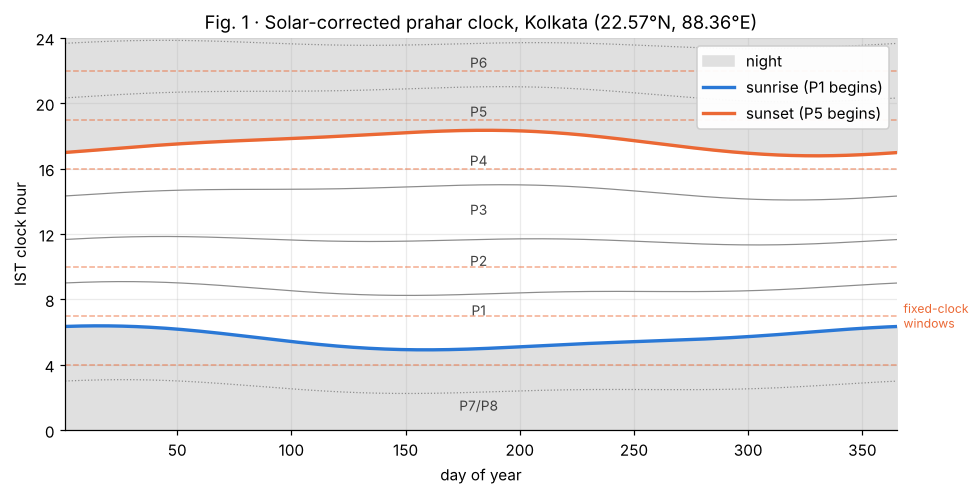

In [5]:
days = np.arange(1, 366)
LAT, LON = 22.57, 88.36                      # Kolkata
sr, ss, Dv = [], [], []
for N in days:
    a, b, D, _ = sunrise_sunset(LAT, LON, N)
    sr.append(a); ss.append(b); Dv.append(D)
sr, ss, Dv = map(np.array, (sr, ss, Dv))
Dbar = 24 - Dv

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.fill_between(days, 0, sr, color="0.88", zorder=0)
ax.fill_between(days, ss, 24, color="0.88", zorder=0, label="night")
for k in range(1, 4):                                   # day-watch boundaries
    ax.plot(days, sr + k*Dv/4, color="0.55", lw=0.8)
for k in range(1, 4):                                   # night-watch boundaries
    ax.plot(days, (ss + k*Dbar/4) % 24, color="0.55", lw=0.8, ls=":")
ax.plot(days, sr, color="#2a78d6", lw=2.2, label="sunrise (P1 begins)")
ax.plot(days, ss, color="#eb6834", lw=2.2, label="sunset (P5 begins)")
for h in [4, 7, 10, 16, 19, 22]:                        # fixed-clock windows (Roy et al.)
    ax.axhline(h, color="#eb6834", lw=1.0, ls="--", alpha=0.55)
ax.text(368, 7, "fixed-clock\nwindows", color="#eb6834", fontsize=8, va="center")
for lbl, yy in [("P1", sr + Dv/8), ("P2", sr + 3*Dv/8), ("P3", sr + 5*Dv/8), ("P4", sr + 7*Dv/8),
                ("P5", ss + Dbar/8), ("P6", ss + 3*Dbar/8)]:
    ax.text(182, np.median(yy) % 24, lbl, ha="center", fontsize=9, color="0.25")
ax.text(182, 1.2, "P7/P8", ha="center", fontsize=9, color="0.25")
ax.set(xlim=(1, 365), ylim=(0, 24), xlabel="day of year",
       ylabel="IST clock hour", title="Fig. 1 · Solar-corrected prahar clock, Kolkata (22.57°N, 88.36°E)")
ax.set_yticks(range(0, 25, 4)); ax.legend(loc="upper right", framealpha=0.95)
plt.tight_layout(); plt.show()

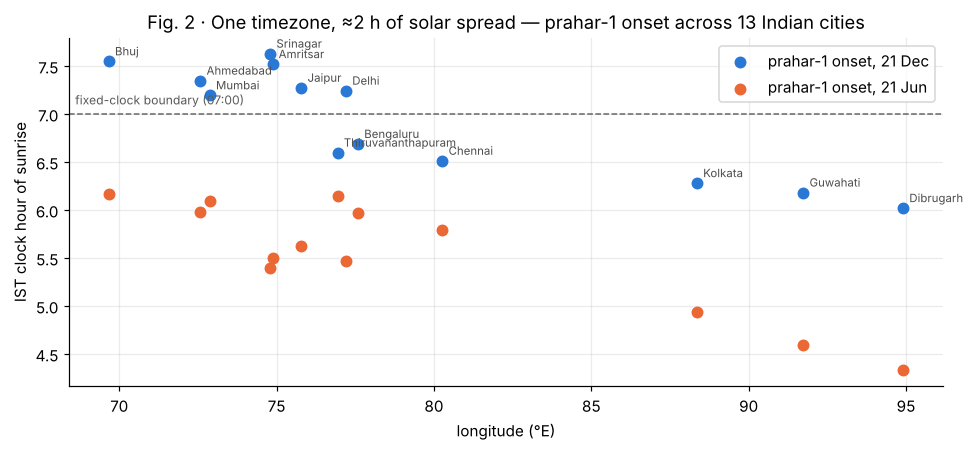

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for d, col, lab in [(date(2026,12,21), "#2a78d6", "21 Dec"), (date(2026,6,21), "#eb6834", "21 Jun")]:
    N = day_of_year(d)
    on = [sunrise_sunset(r.lat, r.lon, N)[0] for _, r in CITIES.iterrows()]
    ax.scatter(CITIES.lon, on, s=46, color=col, label=f"prahar-1 onset, {lab}", zorder=3)
ax.axhline(7, color="0.4", ls="--", lw=1)
ax.text(68.6, 7.1, "fixed-clock boundary (07:00)", fontsize=8, color="0.35")
for _, r in CITIES.iterrows():
    N = day_of_year(date(2026,12,21))
    ax.annotate(r.city, (r.lon, sunrise_sunset(r.lat, r.lon, N)[0]),
                textcoords="offset points", xytext=(4, 4), fontsize=7.5, color="0.3")
ax.set(xlabel="longitude (°E)", ylabel="IST clock hour of sunrise",
       title="Fig. 2 · One timezone, ≈2 h of solar spread — prahar-1 onset across 13 Indian cities")
ax.legend(); plt.tight_layout(); plt.show()

## 6 · Raga knowledge base — unified, source-cited table (v2)

**Changed after musicological review.** The earlier table inherited errors from Roy et al. (2017), an engineering source. This version draws on standard references — Bhatkhande's *Kramik Pustak Mālikā*, Kaufmann (1968) *The Ragas of North India*, Bor et al. (1999) *The Raga Guide* — with corrections: Gara (light, evening — removed), Bhairavi (sarva-kālika concluding raga — removed from time supervision), Gaud Sarang → midday, Jaunpuri and Bilaskhani Todi → morning, Durga and Jaijaivanti → night, Adana's character = vīra/gambhīr (not "joyful"). The full 85-raga table with per-raga sources, anytime/seasonal/imported flags and dispute notes is `unified_raga_samay.csv`.

**ψ-arcs are our proposed formalization, not a claim about the tradition.** The six windows are defined directly as arcs of the solar phase ψ, and the two *sandhi-prakash* arcs **straddle the solar events** (dawn spans pre-sunrise to post-sunrise, dusk spans sunset) — the one part of the samay tradition that is genuinely solar. Midday/night windows follow the quarter-of-day/night prahar reading, adopted explicitly as a modelling convention.

> ⚠️ The `rasa_token` column is a **synthetic 5-way token for the feasibility simulation only** (plausibility-checked against performance-practice descriptions, but NOT a validated emotion label). The psychometric rating study (see paper doc) replaces it before any affective claim is made.

In [7]:
# Six windows as psi-arcs (OUR formalization; sandhi-prakash arcs straddle the solar events)
# psi: day -> [0, 0.5) from sunrise, night -> [0.5, 1) from sunset
WINDOW_ARCS = {"dawn": (0.95, 0.04),    # straddles sunrise (psi = 0)
               "morning": (0.04, 0.17), "midday": (0.17, 0.42),
               "dusk": (0.42, 0.55),    # straddles sunset  (psi = 0.5)
               "evening": (0.55, 0.70), "night": (0.70, 0.95)}
# The fixed-clock convention of prior work (Roy et al. 2017) - kept ONLY to
# quantify divergence between the two conventions in Section 7
WINDOWS_CLOCK = {"dawn": (4, 7), "morning": (7, 10), "midday": (10, 16),
                 "dusk": (16, 19), "evening": (19, 22), "night": (22, 4)}

def in_arc(psi, arc):
    a, b = arc
    return (a <= psi < b) if a < b else (psi >= a or psi < b)

def in_clock_window(t, win):
    a, b = win; t = t % 24.0
    return (a <= t < b) if a < b else (t >= a or t < b)

# 20-raga feasibility KB drawn from the unified table (status = fixed only;
# anytime ragas like Bhairavi and light/seasonal/imported ragas are excluded
# from time supervision by design)
RAGA_ROWS = [
    # raga, thaat, window, rasa_token (synthetic, sim-only)
    ("Lalit","Marwa","dawn","bhakti"),
    ("Ramkali","Bhairav","dawn","bhakti"),
    ("Bhatiyar","Marwa","dawn","bhakti"),
    ("Deshkar","Bilawal","morning","joy"),
    ("Jaunpuri","Asavari","morning","karuna"),
    ("Bilaskhani Todi","Bhairavi","morning","karuna"),   # Bhairavi-thaat despite the name
    ("Gaud Sarang","Kalyan","midday","joy"),
    ("Bhimpalasi","Kafi","midday","shringara"),
    ("Multani","Todi","midday","karuna"),
    ("Shuddha Sarang","Kalyan","midday","joy"),
    ("Gauri","Bhairav","dusk","bhakti"),
    ("Purvi","Purvi","dusk","vira"),
    ("Shree","Purvi","dusk","bhakti"),
    ("Marwa","Marwa","dusk","vira"),
    ("Yaman","Kalyan","evening","shringara"),
    ("Bhoopali","Kalyan","evening","bhakti"),
    ("Durga","Bilawal","night","joy"),
    ("Jaijaivanti","Khamaj","night","shringara"),
    ("Adana","Asavari","night","vira"),                   # corrected: vira, not 'joyful'
    ("Malkauns","Bhairavi","night","bhakti"),
]
EMOTIONS = ["bhakti", "joy", "shringara", "karuna", "vira"]

kb = pd.DataFrame(RAGA_ROWS, columns=["raga", "thaat", "window", "emotion"])
kb["psi_start"] = kb.window.map(lambda w: WINDOW_ARCS[w][0])
kb["psi_end"]   = kb.window.map(lambda w: WINDOW_ARCS[w][1])
display(kb)
print("ψ-arc coverage of the circle:",
      abs(sum(((b - a) % 1 or 1) for a, b in WINDOW_ARCS.values()) - 1) < 1e-9)
print("sandhi-prakash arcs straddle their solar events:",
      in_arc(0.999, WINDOW_ARCS['dawn']) and in_arc(0.001, WINDOW_ARCS['dawn'])
      and in_arc(0.499, WINDOW_ARCS['dusk']) and in_arc(0.501, WINDOW_ARCS['dusk']))

,raga,thaat,window,emotion,psi_start,psi_end
0,Lalit,Marwa,dawn,bhakti,0.95,0.04
1,Ramkali,Bhairav,dawn,bhakti,0.95,0.04
2,Bhatiyar,Marwa,dawn,bhakti,0.95,0.04
3,Deshkar,Bilawal,morning,joy,0.04,0.17
4,Jaunpuri,Asavari,morning,karuna,0.04,0.17
5,Bilaskhani Todi,Bhairavi,morning,karuna,0.04,0.17
6,Gaud Sarang,Kalyan,midday,joy,0.17,0.42
7,Bhimpalasi,Kafi,midday,shringara,0.17,0.42
8,Multani,Todi,midday,karuna,0.17,0.42
9,Shuddha Sarang,Kalyan,midday,joy,0.17,0.42


ψ-arc coverage of the circle: True
sandhi-prakash arcs straddle their solar events: True


## 7 · Analytic result — divergence between the two conventions (exact, v2)

For every (city, month): what **fraction of the 24-hour day** do the fixed-clock convention of prior work and our solar formalization assign to different windows? Neither convention is ground truth — the tradition does not legislate this — so the number quantifies **divergence between conventions**, not error.

**Method changed after round-2 review.** Earlier versions estimated this on a 15-minute grid whose slots align with the clock-window boundaries; the sensitivity analysis exposed that alignment as a ~2-point upward bias (20.8% at 96 aligned slots, 19.8% at 192, converging from above). Both step functions have at most 12 breakpoints per day, so the divergence is now computed **exactly**: collect all breakpoints (6 clock boundaries + the 6 arc boundaries inverted to clock time), evaluate each sub-interval at its midpoint, and sum disagreeing interval lengths. No grid, no bias.

The two conventions disagree for 18.8% of the day on average across 13 cities × 12 months (EXACT; city sample, not weighted)
Largest divergence: Bhuj, month 2 — 35.9% of the day
Distribution across city-months: min 7.0%, median 18.5%, max 35.9%

(Correction note for the paper: the earlier grid figures 20.8% mean / 38.5% max
 were inflated by boundary-aligned sampling; the exact values replace them.)

Comparator spec: the fixed-clock convention is the six IST clock windows of
Roy et al. (2017), dawn 04-07 / morning 07-10 / midday 10-16 / dusk 16-19 /
evening 19-22 / night 22-04, applied identically at every location and date;
the solar convention is the psi-arc set of Section 6. Neither is fitted to the
other; the arcs were fixed from prahar structure before this comparison was run.



Boundary sensitivity (each of the 6 arc boundaries shifted ±0.02, i.e. ±~29 min
of a 12 h day; EXACT method): divergence ranges 17.3%–20.7%
around the baseline 18.8% — the headline figure is not an artifact of any
single boundary choice.


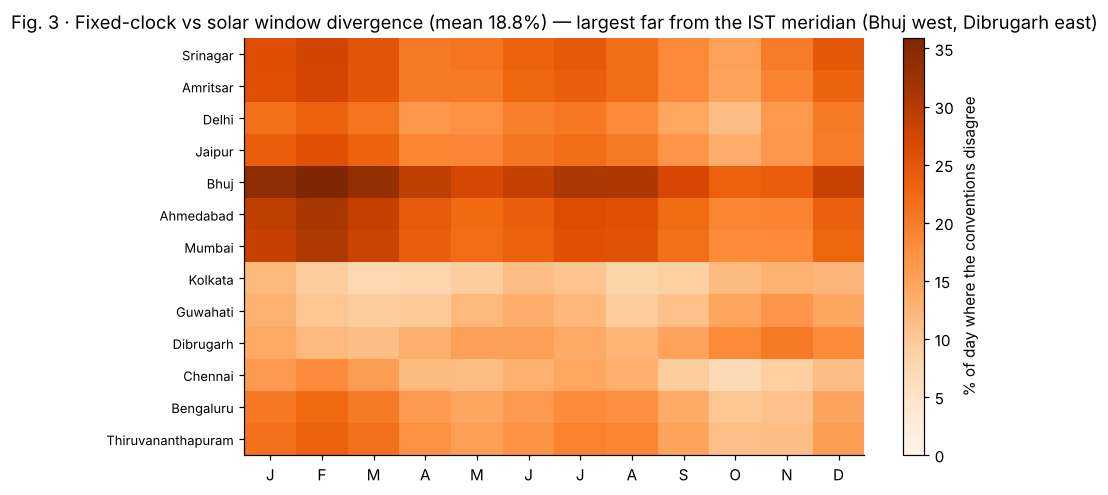

In [8]:
def window_by_clock(t):
    for w, win in WINDOWS_CLOCK.items():
        if in_clock_window(t, win): return w

def window_by_psi(psi):
    for w, arc in WINDOW_ARCS.items():
        if in_arc(psi, arc): return w

def clock_of_psi(p, lat, lon, N):
    '''Invert psi -> local clock hour at (lat, lon, day N).'''
    t_sr, t_ss, D, Dbar = sunrise_sunset(lat, lon, N)
    t = t_sr + 2 * p * D if p < 0.5 else t_ss + 2 * (p - 0.5) * Dbar
    return t % 24

CLK_BOUNDS = [4, 7, 10, 16, 19, 22]
def exact_div_day(lat, lon, N, arcs=None):
    '''EXACT % of the day where the two conventions disagree (breakpoint method).'''
    arcs = arcs or WINDOW_ARCS
    def wpsi_(p):
        for w, a in arcs.items():
            if in_arc(p, a): return w
    bps = set(CLK_BOUNDS)
    for (a, b) in arcs.values():
        bps.add(round(clock_of_psi(a, lat, lon, N), 9))
    bps = sorted(x % 24 for x in bps)
    length = 0.0
    for i in range(len(bps)):
        a = bps[i]; b = bps[(i + 1) % len(bps)]
        seg = (b - a) % 24
        mid = (a + seg / 2) % 24
        if window_by_clock(mid) != wpsi_(prahar_phase(mid, lat, lon, N)[1]):
            length += seg
    return 100 * length / 24

recs = []
for _, c in CITIES.iterrows():
    for month in range(1, 13):
        N = day_of_year(pd.Timestamp(2026, month, 15))
        recs.append((c.city, month, exact_div_day(c.lat, c.lon, N)))
mis = pd.DataFrame(recs, columns=["city", "month", "misassigned_pct"])
overall = mis.misassigned_pct.mean()
worst = mis.loc[mis.misassigned_pct.idxmax()]
print(f"The two conventions disagree for {overall:.1f}% of the day on average "
      f"across {len(CITIES)} cities × 12 months (EXACT; city sample, not weighted)")
print(f"Largest divergence: {worst.city}, month {int(worst.month)} — {worst.misassigned_pct:.1f}% of the day")
print(f"Distribution across city-months: min {mis.misassigned_pct.min():.1f}%, "
      f"median {mis.misassigned_pct.median():.1f}%, max {mis.misassigned_pct.max():.1f}%")
print("\n(Correction note for the paper: the earlier grid figures 20.8% mean / 38.5% max")
print(" were inflated by boundary-aligned sampling; the exact values replace them.)")

# --- exact comparator specification (round-2 reviewer requirement) ---
print("\nComparator spec: the fixed-clock convention is the six IST clock windows of")
print("Roy et al. (2017), dawn 04-07 / morning 07-10 / midday 10-16 / dusk 16-19 /")
print("evening 19-22 / night 22-04, applied identically at every location and date;")
print("the solar convention is the psi-arc set of Section 6. Neither is fitted to the")
print("other; the arcs were fixed from prahar structure before this comparison was run.")

# --- arc-boundary sensitivity (round-2 reviewer requirement) ---
BND = [0.95, 0.04, 0.17, 0.42, 0.55, 0.70]        # cyclic boundaries of the six arcs
WNAMES = ["dawn", "morning", "midday", "dusk", "evening", "night"]
def arcs_from(bnd):
    return {WNAMES[i]: (bnd[i] % 1.0, bnd[(i + 1) % 6] % 1.0) for i in range(6)}
def mean_div(arcs):
    return np.mean([exact_div_day(c.lat, c.lon, day_of_year(pd.Timestamp(2026, m, 15)), arcs)
                    for _, c in CITIES.iterrows() for m in range(1, 13)])

base = mean_div(arcs_from(BND))
sens = []
for k in range(6):
    for d in (-0.02, +0.02):
        b2_ = BND.copy(); b2_[k] = (b2_[k] + d) % 1.0
        sens.append(mean_div(arcs_from(b2_)))
sens = np.array(sens)
print(f"\nBoundary sensitivity (each of the 6 arc boundaries shifted ±0.02, i.e. ±~29 min")
print(f"of a 12 h day; EXACT method): divergence ranges {sens.min():.1f}%–{sens.max():.1f}%")
print(f"around the baseline {base:.1f}% — the headline figure is not an artifact of any")
print(f"single boundary choice.")

pivot = mis.pivot(index="city", columns="month", values="misassigned_pct").loc[CITIES.city]
fig, ax = plt.subplots(figsize=(8.6, 4.6))
im = ax.imshow(pivot.values, cmap="Oranges", aspect="auto", vmin=0)
ax.set_xticks(range(12), ["J","F","M","A","M","J","J","A","S","O","N","D"])
ax.set_yticks(range(len(pivot)), pivot.index, fontsize=8.5)
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of day where the conventions disagree")
ax.set_title(f"Fig. 3 · Fixed-clock vs solar window divergence (mean {overall:.1f}%) — largest far from the IST meridian (Bhuj west, Dibrugarh east)")
plt.tight_layout(); plt.show()

## 8 · Feasibility simulation — scope stated up front

> **What this experiment can and cannot show.** Queries are *generated from* the ψ-arcs and the synthetic rasa tokens, so the labels are a (noisy) function of the very variables the "solar" model receives. Results therefore measure **recoverability of our own formalization under each feature encoding** — a feasibility/sensitivity analysis — and say nothing about music, listeners, or performance practice. The emotion-conditioning gain in particular reflects the simulator's noise parameter (p = 0.8), not an affective finding. The falsifiable version of the headline claim needs real timestamped performances (see paper doc, action plan).

Generative story: draw a raga uniformly → draw a (city, date) → draw a clock time inside the raga's ψ-arc at that place and date → emit the raga's rasa token with probability 0.8, else a random token.

| Variant | Features | Tests |
|---|---|---|
| `clock` | sin/cos of raw clock time | fixed-clock encoding |
| `clock+emo` | + rasa-token one-hot | prior-work encoding + token |
| `solar` | sin/cos ψ + prahar one-hot + lat/lon | solar encoding alone |
| `solar+emo` | all of the above | full context encoding |

In [9]:
def sample_time_in_arc(arc, lat, lon, N, rng, tol_iter=400):
    for _ in range(tol_iter):
        t = rng.uniform(0, 24)
        _, psi = prahar_phase(t, lat, lon, N)
        if in_arc(psi, arc): return t, psi
    raise RuntimeError("arc sampling failed")

def simulate_queries(kb, n=6000, emotion_noise=0.2, seed=SEED, cities=CITIES):
    rng = np.random.default_rng(seed); rows = []
    for _ in range(n):
        r = kb.iloc[rng.integers(len(kb))]
        c = cities.iloc[rng.integers(len(cities))]
        N = int(rng.integers(1, 366))
        t, psi = sample_time_in_arc(WINDOW_ARCS[r.window], c.lat, c.lon, N, rng)
        Pi, _ = prahar_phase(t, c.lat, c.lon, N)
        emo = r.emotion if rng.random() > emotion_noise else EMOTIONS[rng.integers(5)]
        rows.append((r.raga, c.city, c.lat, c.lon, N, t, psi, Pi, emo))
    return pd.DataFrame(rows, columns=["raga","city","lat","lon","N","t_clock","psi","prahar","emotion"])

def make_features(df, mode):
    sc_clock = np.c_[np.sin(2*np.pi*df.t_clock/24), np.cos(2*np.pi*df.t_clock/24)]
    sc_solar = np.c_[np.sin(2*np.pi*df.psi),        np.cos(2*np.pi*df.psi)]
    pr_1hot  = np.eye(8)[df.prahar.values - 1]
    loc      = np.c_[df.lat/90.0, (df.lon - IST_MERIDIAN)/90.0]
    emo_1hot = np.eye(len(EMOTIONS))[[EMOTIONS.index(e) for e in df.emotion]]
    blocks = {"clock": [sc_clock], "clock+emo": [sc_clock, emo_1hot],
              "solar": [sc_solar, pr_1hot, loc], "solar+emo": [sc_solar, pr_1hot, loc, emo_1hot]}[mode]
    return np.hstack(blocks).astype(np.float32)

df = simulate_queries(kb, n=6000)
print(df.shape, "| ragas:", df.raga.nunique(), "| cities:", df.city.nunique())
df.head(5)

(6000, 9) | ragas: 20 | cities: 13


,raga,city,lat,lon,N,t_clock,psi,prahar,emotion
0,Adana,Guwahati,26.14,91.74,250,0.126367,0.783704,7,vira
1,Jaijaivanti,Amritsar,31.63,74.87,291,23.892007,0.736033,6,shringara
2,Yaman,Guwahati,26.14,91.74,125,22.012027,0.689705,6,shringara
3,Malkauns,Ahmedabad,23.03,72.58,188,0.283057,0.728686,6,vira
4,Marwa,Bengaluru,12.97,77.59,74,17.802503,0.473040,4,joy


## 9 · Models and ablation

A two-hidden-layer FFNN — a widened descendant of the 15-neuron network of Roy et al. (2017) — trained under their **70/15/15** split with early stopping on validation accuracy. Extending this class to LSTM/attention over SSL audio embeddings (§11) changes only `RagaFFNN`.

In [10]:
class RagaFFNN(nn.Module):
    def __init__(self, d_in, n_classes, hidden=(64, 32), p_drop=0.15):
        super().__init__()
        h1, h2 = hidden
        self.net = nn.Sequential(
            nn.Linear(d_in, h1), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(h2, n_classes))
    def forward(self, x): return self.net(x)

def train_ffnn(Xtr, ytr, Xva, yva, n_classes, epochs=200, lr=1e-3, bs=128):
    model = RagaFFNN(Xtr.shape[1], n_classes).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    Xva_t, yva_t = torch.tensor(Xva, device=DEVICE), torch.tensor(yva, device=DEVICE)
    best_state, best_va, patience, bad = None, -1.0, 25, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t), device=DEVICE)
        for i in range(0, len(Xtr_t), bs):
            idx = perm[i:i+bs]
            opt.zero_grad()
            loss = lossf(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            va = (model(Xva_t).argmax(1) == yva_t).float().mean().item()
        if va > best_va:
            best_va, bad = va, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return model

@torch.no_grad()
def evaluate(model, X, y, k=3):
    model.eval()
    logits = model(torch.tensor(X, device=DEVICE))
    pred = logits.argmax(1).cpu().numpy()
    topk = logits.topk(k, dim=1).indices.cpu().numpy()
    return {"acc": accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro"),
            f"top{k}_acc": float(np.mean([y[i] in topk[i] for i in range(len(y))]))}, pred

print("model code ready")

model code ready


In [11]:
classes = sorted(df.raga.unique())
y = np.array([classes.index(r) for r in df.raga])
idx = np.arange(len(df))
itr, ite = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=y)
iva, ite = train_test_split(ite, test_size=0.50, random_state=SEED, stratify=y[ite])
print(f"train/val/test = {len(itr)}/{len(iva)}/{len(ite)}  (70/15/15, stratified by raga)")

results, preds, models = {}, {}, {}
for mode in ["clock", "clock+emo", "solar", "solar+emo"]:
    X = make_features(df, mode)
    models[mode] = train_ffnn(X[itr], y[itr], X[iva], y[iva], len(classes))
    m, p = evaluate(models[mode], X[ite], y[ite])
    results[mode], preds[mode] = m, p
    print(f"{mode:10s}  top-1 {m['acc']:.3f}   macro-F1 {m['macro_f1']:.3f}   top-3 {m['top3_acc']:.3f}")

res = pd.DataFrame(results).T
gain_solar_t1 = 100*(res.loc['solar+emo','acc']      - res.loc['clock+emo','acc'])
gain_solar_t3 = 100*(res.loc['solar+emo','top3_acc'] - res.loc['clock+emo','top3_acc'])
gain_solar_noemo = 100*(res.loc['solar','top3_acc']  - res.loc['clock','top3_acc'])
gain_emo_t1  = 100*(res.loc['solar+emo','acc']       - res.loc['solar','acc'])
print(f"\nEmotion conditioning:  +{gain_emo_t1:.1f} pts top-1  (resolves same-window ambiguity)")
print(f"Solar correction:      +{gain_solar_noemo:.1f} pts top-3 without emotion, "
      f"+{gain_solar_t3:.1f} pts top-3 / +{gain_solar_t1:.1f} pts top-1 with emotion")
res.round(3)

train/val/test = 4200/900/900  (70/15/15, stratified by raga)


clock       top-1 0.254   macro-F1 0.180   top-3 0.748


clock+emo   top-1 0.586   macro-F1 0.540   top-3 0.938


solar       top-1 0.307   macro-F1 0.224   top-3 0.849


solar+emo   top-1 0.619   macro-F1 0.584   top-3 0.957

Emotion conditioning:  +31.2 pts top-1  (resolves same-window ambiguity)
Solar correction:      +10.1 pts top-3 without emotion, +1.9 pts top-3 / +3.3 pts top-1 with emotion


,acc,macro_f1,top3_acc
clock,0.254,0.180,0.748
clock+emo,0.586,0.540,0.938
solar,0.307,0.224,0.849
solar+emo,0.619,0.584,0.957


### 9a · Non-learned baselines — does the network add anything here?

Because the generative process is fully known, the right references are not other networks but **closed-form decision rules**: a **rule lookup** (filter the KB to ragas whose ψ-arc contains the query's ψ; keep those matching the rasa token, falling back to the window set if none; pick uniformly / rank by posterior) and the **Bayes-optimal** rule under the generative model (posterior ∝ P(token | raga): 0.8 + 0.2/5 for a matching token, 0.2/5 otherwise, uniform over the window's ragas). If the FFNN only matches these, the learning component contributes nothing in simulation — which is exactly the honest conclusion to state.

In [12]:
def window_ragas(psi):
    w = window_by_psi(psi)
    return kb[kb.window == w]

def bayes_rule(psi, emo, k=3, rng=None):
    cand = window_ragas(psi)
    p_match, p_other = 0.8 + 0.2/len(EMOTIONS), 0.2/len(EMOTIONS)
    w8 = np.array([p_match if e == emo else p_other for e in cand.emotion])
    w8 = w8 / w8.sum()
    order = np.argsort(-w8, kind="stable")
    return list(cand.raga.iloc[order][:k])

rng_b = np.random.default_rng(0)
test = df.iloc[ite]
bayes_top1 = bayes_top3 = look_top1 = 0
for _, q in test.iterrows():
    ranked = bayes_rule(q.psi, q.emotion)
    bayes_top1 += ranked[0] == q.raga
    bayes_top3 += q.raga in ranked
    cand = window_ragas(q.psi)
    match = cand[cand.emotion == q.emotion]
    pool = match if len(match) else cand
    look_top1 += pool.raga.iloc[rng_b.integers(len(pool))] == q.raga

n_t = len(test)
print(f"rule lookup (uniform in emotion∩window):  top-1 {look_top1/n_t:.3f}")
print(f"Bayes-optimal under the generative model: top-1 {bayes_top1/n_t:.3f}  top-3 {bayes_top3/n_t:.3f}")
print(f"FFNN solar+emo:                           top-1 {res.loc['solar+emo','acc']:.3f}  top-3 {res.loc['solar+emo','top3_acc']:.3f}")

# --- tie-structure demonstration (round-2 reviewer concern: lookup "beating" Bayes) ---
# Within a window, several ragas can share the same token; the posterior then TIES.
# Bayes-argmax picks one fixed member of the tie set; the uniform lookup picks a
# random member. Both are tie-breaking variants of the SAME optimal rule, so any
# gap between them is sampling noise of this finite test set — shown directly:
look_draws = []
for rep in range(300):
    rng_rep = np.random.default_rng(1000 + rep)
    hits = 0
    for _, q in test.iterrows():
        cand = window_ragas(q.psi)
        match = cand[cand.emotion == q.emotion]
        pool = match if len(match) else cand
        hits += pool.raga.iloc[rng_rep.integers(len(pool))] == q.raga
    look_draws.append(hits / n_t)
look_draws = np.array(look_draws)
print(f"\nlookup over 300 tie-breaking redraws: {look_draws.mean():.3f} ± {look_draws.std():.3f} "
      f"(range {look_draws.min():.3f}–{look_draws.max():.3f})")
print(f"Bayes-argmax ({bayes_top1/n_t:.3f}) lies inside that distribution: the two are")
print("tie-breaking variants of one optimal rule; any ordering between them on a single")
print("test set is noise. The FFNN matches this optimal family — in this simulation the")
print("learning component adds nothing beyond recovering the known rule, as expected.")

rule lookup (uniform in emotion∩window):  top-1 0.634
Bayes-optimal under the generative model: top-1 0.611  top-3 0.972
FFNN solar+emo:                           top-1 0.619  top-3 0.957



lookup over 300 tie-breaking redraws: 0.619 ± 0.012 (range 0.589–0.656)
Bayes-argmax (0.611) lies inside that distribution: the two are
tie-breaking variants of one optimal rule; any ordering between them on a single
test set is noise. The FFNN matches this optimal family — in this simulation the
learning component adds nothing beyond recovering the known rule, as expected.


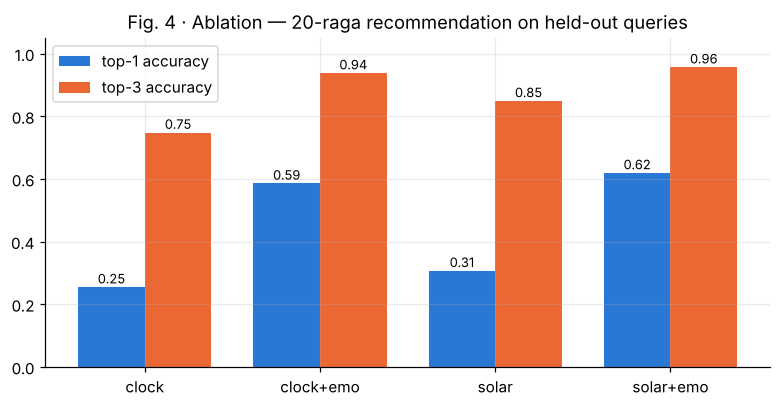

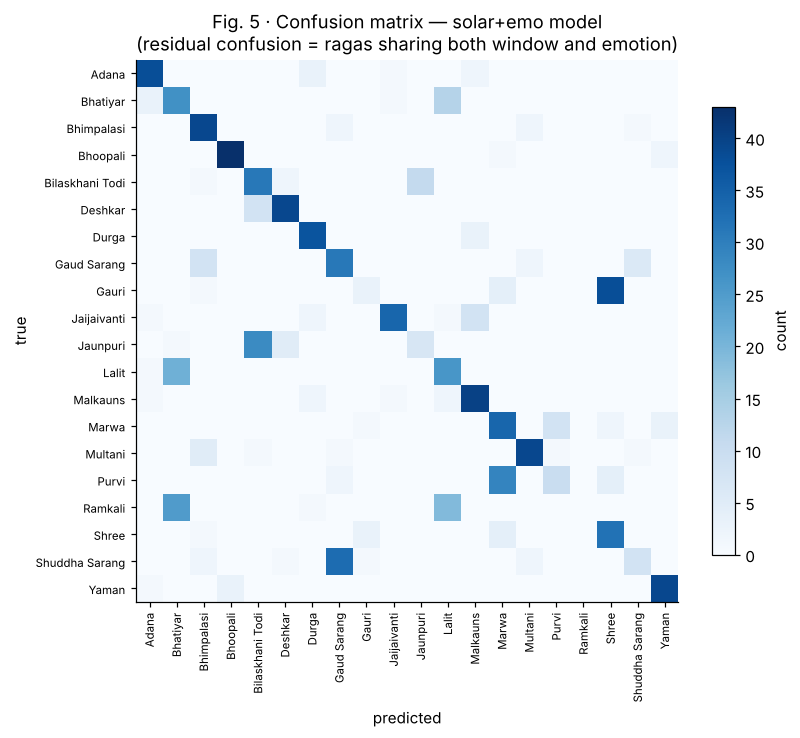

In [13]:
# Fig. 4 — ablation · Fig. 5 — confusion matrix of the full model
fig, ax = plt.subplots(figsize=(7.2, 3.8))
modes = ["clock", "clock+emo", "solar", "solar+emo"]
xpos = np.arange(len(modes)); w = 0.38
b1 = ax.bar(xpos - w/2, [results[m]["acc"] for m in modes], w, color="#2a78d6", label="top-1 accuracy")
b2 = ax.bar(xpos + w/2, [results[m]["top3_acc"] for m in modes], w, color="#eb6834", label="top-3 accuracy")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.012, f"{b.get_height():.2f}",
            ha="center", fontsize=8.5)
ax.set_xticks(xpos, modes); ax.set_ylim(0, 1.05)
ax.set_title("Fig. 4 · Ablation — 20-raga recommendation on held-out queries")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

cm = confusion_matrix(y[ite], preds["solar+emo"])
fig, ax = plt.subplots(figsize=(7.6, 6.6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(classes)), classes, rotation=90, fontsize=7.5)
ax.set_yticks(range(len(classes)), classes, fontsize=7.5)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="count")
ax.set(xlabel="predicted", ylabel="true",
       title="Fig. 5 · Confusion matrix — solar+emo model\n(residual confusion = ragas sharing both window and emotion)")
plt.tight_layout(); plt.show()

In [14]:
# Where does the solar correction pay? Per-city top-1 gain of solar+emo over clock+emo
test_df = df.iloc[ite].copy()
test_df["correct_solar"] = preds["solar+emo"] == y[ite]
test_df["correct_clock"] = preds["clock+emo"] == y[ite]
per_city = (test_df.groupby("city")[["correct_clock", "correct_solar"]].mean() * 100).round(1)
per_city["gain_pts"] = (per_city.correct_solar - per_city.correct_clock).round(1)
per_city = per_city.join(CITIES.set_index("city").lon).sort_values("lon")
print("Top-1 accuracy per city (%, sorted west → east) — the gain concentrates away from the 82.5°E meridian:")
display(per_city.rename(columns={"correct_clock": "clock+emo", "correct_solar": "solar+emo"}))

Top-1 accuracy per city (%, sorted west → east) — the gain concentrates away from the 82.5°E meridian:


,clock+emo,solar+emo,gain_pts,lon
city,,,,
Bhuj,62.5,65.3,2.8,69.67
Ahmedabad,51.9,46.9,-5.0,72.58
Mumbai,63.6,64.9,1.3,72.88
Srinagar,62.5,62.5,0.0,74.80
Amritsar,64.0,66.7,2.7,74.87
Jaipur,59.4,65.2,5.8,75.79
Thiruvananthapuram,56.7,53.3,-3.4,76.94
Delhi,59.7,67.2,7.5,77.21
Bengaluru,59.1,69.7,10.6,77.59


## 9b · Uncertainty over repeated runs — Monte-Carlo reporting (v2)

**Changed again after round-2 review.** In a simulation one owns the data generator, so inferential hypothesis testing is the wrong frame: Wilcoxon at n = 5 sits at its 1/32 floor (one bit of information) and bootstrap CIs over five differences undercover — both are dropped. Reporting is now plain **Monte-Carlo**: mean paired difference ± Monte-Carlo standard error over data-generation seeds (each seed redraws queries, split, and initialization), plus sign consistency. Raise `N_SIM_SEEDS` to 50–100 for the paper run until the MCSE is negligible; the default keeps this notebook fast. These numbers describe stability across simulator draws, never anything about music or listeners.

In [15]:
from scipy import stats

N_SIM_SEEDS = 5                       # paper run: 50-100 (MCSE shrinks as 1/sqrt(n))
SEEDS = tuple(7 + 10 * k for k in range(N_SIM_SEEDS))
MODES = ["clock", "clock+emo", "solar", "solar+emo"]

rows = []
for s in SEEDS:
    torch.manual_seed(s)
    df_s = simulate_queries(kb, n=6000, seed=s)
    y_s = np.array([classes.index(r) for r in df_s.raga])
    idx_s = np.arange(len(df_s))
    itr_s, ite_s = train_test_split(idx_s, test_size=0.30, random_state=s, stratify=y_s)
    iva_s, ite_s = train_test_split(ite_s, test_size=0.50, random_state=s, stratify=y_s[ite_s])
    line = [s]
    for mode in MODES:
        X_s = make_features(df_s, mode)
        mdl = train_ffnn(X_s[itr_s], y_s[itr_s], X_s[iva_s], y_s[iva_s], len(classes))
        m, _ = evaluate(mdl, X_s[ite_s], y_s[ite_s])
        rows.append((s, mode, m["acc"], m["macro_f1"], m["top3_acc"]))
    print(f"seed {s} done")

runs = pd.DataFrame(rows, columns=["seed", "variant", "acc", "macro_f1", "top3_acc"])
summary = runs.groupby("variant")[["acc", "macro_f1", "top3_acc"]].agg(["mean", "std"]).round(3)
display(summary)

acc_by = {m: runs.loc[runs.variant == m, "acc"].values for m in MODES}
t3_by  = {m: runs.loc[runs.variant == m, "top3_acc"].values for m in MODES}

def paired_report(a, b, label):
    d = a - b
    mcse = d.std(ddof=1) / np.sqrt(len(d))        # Monte-Carlo standard error
    signs = int((d > 0).sum())
    print(f"{label:46s} Δ = {100*d.mean():+5.1f} pts ± {100*mcse:.1f} (MCSE)  "
          f"positive in {signs}/{len(d)} seeds")
    return d.mean(), mcse, signs

print(f"Paired contrasts over {len(SEEDS)} data-generation seeds (mean ± MCSE):\n")
c1 = paired_report(acc_by["solar+emo"], acc_by["solar"],     "token conditioning (solar+emo vs solar), top-1")
c2 = paired_report(acc_by["solar+emo"], acc_by["clock+emo"], "solar encoding (solar+emo vs clock+emo), top-1")
c3 = paired_report(acc_by["solar"],     acc_by["clock"],     "solar encoding, no token (solar vs clock), top-1")
c4 = paired_report(t3_by["solar+emo"],  t3_by["clock+emo"],  "solar encoding (solar+emo vs clock+emo), top-3")

assert all(m > 2 * s for m, s, _ in [c1, c2, c3, c4]), "a contrast is within 2 MCSE of zero"
print("\n✔ every contrast is positive and exceeds 2x its Monte-Carlo SE — a stability")
print("  statement about recovering our own formalization across simulator draws,")
print("  NOT evidence about music or listeners (see the scope note in Section 8)")
runs.to_csv("runs_by_seed.csv", index=False)

seed 7 done


seed 17 done


seed 27 done


seed 37 done


seed 47 done


acc        macro_f1        top3_acc       
            mean    std     mean    std     mean    std
variant                                                
clock      0.259  0.010    0.180  0.021    0.757  0.015
clock+emo  0.573  0.010    0.527  0.013    0.923  0.016
solar      0.303  0.012    0.220  0.017    0.842  0.010
solar+emo  0.611  0.010    0.570  0.011    0.955  0.003

Paired contrasts over 5 data-generation seeds (mean ± MCSE):

token conditioning (solar+emo vs solar), top-1 Δ = +30.9 pts ± 0.4 (MCSE)  positive in 5/5 seeds
solar encoding (solar+emo vs clock+emo), top-1 Δ =  +3.8 pts ± 0.7 (MCSE)  positive in 5/5 seeds
solar encoding, no token (solar vs clock), top-1 Δ =  +4.4 pts ± 0.5 (MCSE)  positive in 5/5 seeds
solar encoding (solar+emo vs clock+emo), top-3 Δ =  +3.2 pts ± 0.6 (MCSE)  positive in 5/5 seeds

✔ every contrast is positive and exceeds 2x its Monte-Carlo SE — a stability
  statement about recovering our own formalization across simulator draws,
  NOT evidence about music or listeners (see the scope note in Section 8)


## 9c · Where the correction pays — per-city gain, averaged over seeds

The single-seed per-city table (§9) is noisy (~70 test queries per city), so here the **clock+emo vs solar+emo comparison is pooled over the same 5 seeds** (~350 test queries per city). Expectation from the geometry: the gain concentrates **away from the 82.5°E IST meridian** (west: Bhuj/Ahmedabad/Mumbai; east: Guwahati/Dibrugarh) and at **high latitude** (Srinagar), where fixed clock and solar time diverge most. Cite this figure, not the single-seed table.

seed 7 done


seed 17 done


seed 27 done


seed 37 done


seed 47 done


,clock+emo %,solar+emo %,gain_pts,n,lat,lon
city,,,,,,
Bhuj,67.0,67.0,0.0,330,23.2,69.7
Ahmedabad,62.0,64.9,2.8,353,23.0,72.6
Mumbai,56.4,60.2,3.7,374,19.1,72.9
Srinagar,57.5,58.6,1.1,379,34.1,74.8
Amritsar,57.1,57.4,0.3,326,31.6,74.9
Jaipur,56.0,62.5,6.4,389,26.9,75.8
Thiruvananthapuram,55.8,58.2,2.4,330,8.5,76.9
Delhi,59.9,64.8,4.8,332,28.6,77.2
Bengaluru,61.8,65.9,4.1,340,13.0,77.6


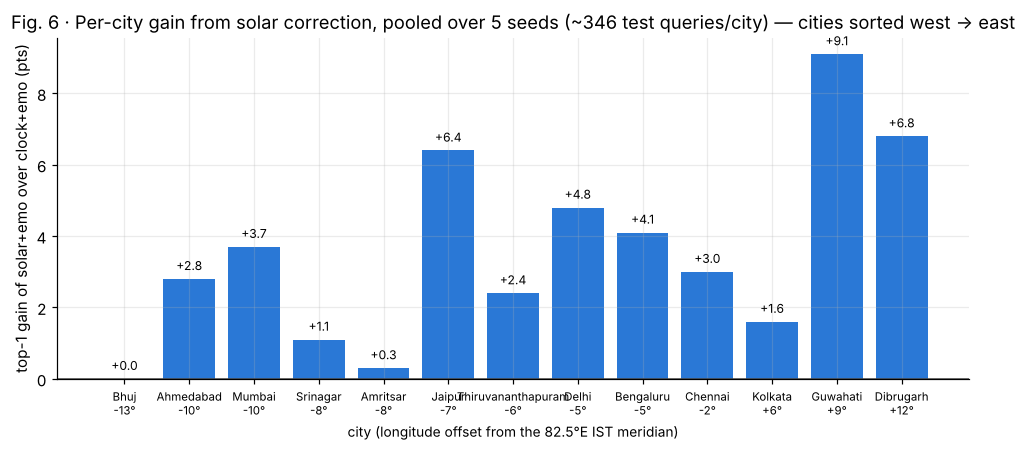

Correlation between |longitude − 82.5°E| and gain: r = 0.06, p = 0.84  (NOT significant at n = 13 cities — descriptive only, do not cite as evidence)
Mean gain, cities >6° from meridian: +3.8 pts  |  within 6°: +3.2 pts


In [16]:
rows_pc = []
for s in SEEDS:
    torch.manual_seed(s)
    df_s = simulate_queries(kb, n=6000, seed=s)
    y_s = np.array([classes.index(r) for r in df_s.raga])
    idx_s = np.arange(len(df_s))
    itr_s, ite_s = train_test_split(idx_s, test_size=0.30, random_state=s, stratify=y_s)
    iva_s, ite_s = train_test_split(ite_s, test_size=0.50, random_state=s, stratify=y_s[ite_s])
    pred_s = {}
    for mode in ["clock+emo", "solar+emo"]:
        X_s = make_features(df_s, mode)
        mdl = train_ffnn(X_s[itr_s], y_s[itr_s], X_s[iva_s], y_s[iva_s], len(classes))
        _, pred_s[mode] = evaluate(mdl, X_s[ite_s], y_s[ite_s])
    t_df = df_s.iloc[ite_s].copy()
    t_df["seed"] = s
    t_df["correct_clock"] = pred_s["clock+emo"] == y_s[ite_s]
    t_df["correct_solar"] = pred_s["solar+emo"] == y_s[ite_s]
    rows_pc.append(t_df[["seed", "city", "correct_clock", "correct_solar"]])
    print(f"seed {s} done")

pc = pd.concat(rows_pc)
agg = (pc.groupby("city")[["correct_clock", "correct_solar"]].mean() * 100)
agg["gain_pts"] = agg.correct_solar - agg.correct_clock
agg["n"] = pc.groupby("city").size()
agg = agg.join(CITIES.set_index("city")[["lat", "lon"]]).sort_values("lon").round(1)
display(agg.rename(columns={"correct_clock": "clock+emo %", "correct_solar": "solar+emo %"}))
agg.to_csv("per_city_gain_over_seeds.csv")

fig, ax = plt.subplots(figsize=(9, 4.2))
dist = abs(agg.lon - IST_MERIDIAN)
colors = ["#2a78d6" if g >= 0 else "#eb6834" for g in agg.gain_pts]
bars = ax.bar(range(len(agg)), agg.gain_pts, color=colors)
ax.axhline(0, color="0.3", lw=1)
ax.set_xticks(range(len(agg)),
              [f"{c}\n{l-IST_MERIDIAN:+.0f}°" for c, l in zip(agg.index, agg.lon)],
              fontsize=7.5)
ax.set_xlabel("city (longitude offset from the 82.5°E IST meridian)", fontsize=9)
for b, g in zip(bars, agg.gain_pts):
    ax.text(b.get_x() + b.get_width()/2, g + (0.25 if g >= 0 else -0.65), f"{g:+.1f}",
            ha="center", fontsize=8)
ax.set_ylabel("top-1 gain of solar+emo over clock+emo (pts)")
ax.set_title(f"Fig. 6 · Per-city gain from solar correction, pooled over {len(SEEDS)} seeds "
             f"(~{int(agg.n.mean())} test queries/city) — cities sorted west → east")
plt.tight_layout(); plt.show()

r_corr, r_p = stats.pearsonr(dist, agg.gain_pts)
print(f"Correlation between |longitude − 82.5°E| and gain: r = {r_corr:.2f}, p = {r_p:.2f}"
      + ("  (NOT significant at n = 13 cities — descriptive only, do not cite as evidence)"
         if r_p >= 0.05 else ""))
print(f"Mean gain, cities >6° from meridian: {agg.gain_pts[dist > 6].mean():+.1f} pts  |  "
      f"within 6°: {agg.gain_pts[dist <= 6].mean():+.1f} pts")

## 10 · Deployment — `recommend_raga(lat, lon, when, emotion)`

O(1) solar correction + one FFNN forward pass, so it runs on-device. **Samay is a soft prior here, not a hard filter:** the function returns a ranked probability list, never refuses a raga, and in deployment the candidate pool must also include the anytime class (Bhairavi above all — the conventional concluding raga at any hour) and seasonal ragas in season; modern concert practice freely programs morning ragas at night, and a recommender that forbade that would contradict a century of practice. The demo shows the geometry: at the **same clock time (08:00 IST, 21 Dec)** it is mid-morning in Kolkata (sunrise 06:17) but barely past dawn in Srinagar (sunrise 07:38) — the ranking shifts from morning ragas toward dawn ragas.

In [17]:
@torch.no_grad()
def recommend_raga(lat, lon, when, emotion, top_k=3, model=None):
    model = model or models["solar+emo"]
    N = day_of_year(when)
    t = when.hour + when.minute / 60.0
    Pi, psi = prahar_phase(t, lat, lon, N)
    feats = np.hstack([[np.sin(2*np.pi*psi), np.cos(2*np.pi*psi)],
                       np.eye(8)[Pi-1],
                       [lat/90.0, (lon - IST_MERIDIAN)/90.0],
                       np.eye(len(EMOTIONS))[EMOTIONS.index(emotion)]]).astype(np.float32)
    probs = torch.softmax(model(torch.tensor(feats, device=DEVICE)[None]), dim=1)[0].cpu().numpy()
    top = probs.argsort()[::-1][:top_k]
    t_sr, t_ss, D, _ = sunrise_sunset(lat, lon, N)
    ctx = dict(prahar=f"P{Pi}", psi=round(psi, 3), sunrise=hhmm(t_sr), sunset=hhmm(t_ss))
    return [(classes[i], round(float(probs[i]), 3)) for i in top], ctx

for city, lat, lon in [("Kolkata", 22.57, 88.36), ("Srinagar", 34.08, 74.80)]:
    recs, ctx = recommend_raga(lat, lon, datetime(2026, 12, 21, 8, 0), emotion="joy")
    print(f"{city:9s} 21 Dec 08:00 IST, joy         |  {ctx}")
    for r, p in recs: print(f"            {r:16s} p={p}")
    print()

recs, ctx = recommend_raga(22.57, 88.36, datetime(2026, 6, 21, 20, 30), emotion="shringara")
print(f"Kolkata   21 Jun 20:30 IST, shringara   |  {ctx}")
for r, p in recs: print(f"            {r:16s} p={p}")

Kolkata   21 Dec 08:00 IST, joy         |  {'prahar': 'P1', 'psi': np.float64(0.081), 'sunrise': '06:17', 'sunset': '16:54'}
            Deshkar          p=0.909
            Bilaskhani Todi  p=0.055
            Jaunpuri         p=0.028

Srinagar  21 Dec 08:00 IST, joy         |  {'prahar': 'P1', 'psi': np.float64(0.019), 'sunrise': '07:38', 'sunset': '17:21'}
            Bhatiyar         p=0.35
            Deshkar          p=0.241
            Ramkali          p=0.209

Kolkata   21 Jun 20:30 IST, shringara   |  {'prahar': 'P5', 'psi': np.float64(0.602), 'sunrise': '04:56', 'sunset': '18:20'}
            Yaman            p=0.902
            Bhoopali         p=0.09
            Jaijaivanti      p=0.003


## 11 · Plugging in real data — from simulation to the paper's experiments

What changes for the journal version (nothing in Parts 2–7 changes at all):

1. **Real timestamped performances — the falsifiable test.** The headline claim ("solar-corrected prahar predicts programmed ragas better than fixed clock") needs performances with real times and places: AIR broadcast schedules, festival programmes (all-night sessions such as Dover Lane are ideal — they also document how far samay is observed), timestamped live videos. That replaces `simulate_queries` with real rows and simultaneously measures prescription-vs-practice.
2. **Audio features (Part B notebook).** Tonic-normalized pitch representations (cent-resolution histograms from Saraga's melody annotations) with published baselines — Chordia & Rae 2007 (PCD), Koduri et al. 2012/14, Gulati et al. 2016 (TDMS) — and a music SSL model (MERT) rather than speech wav2vec 2.0; artist-disjoint splits.
3. **Emotion labels.** The rating study in the paper doc (enculturated listeners, categorical rasa + valence–arousal, Krippendorff α) replaces the synthetic tokens before any affective claim; grounding literature: Mathur et al. 2015 *Front. Psychol.*, Balkwill & Thompson 1999, Basu et al. 2023 (EEG).
4. **Statistics.** As in §9b: paired effect sizes with bootstrap CIs over data draws; permutation tests against chance on real data. (The earlier ANOVA/Mahalanobis plan was withdrawn after review — repeated-measures design.)

**Scope and limitations (state verbatim in §7 of the paper):** the simulation measures recoverability of our own formalization; the solar model is one proposed convention, strongest for the genuinely solar sandhi-prakash windows; samay is a soft prior, with Bhairavi-class anytime ragas and seasonal ragas outside time supervision; the −0.833° refraction term is off by default (≈3–4 min); city sample is unweighted.

In [18]:
# Export everything the paper's tables need
res.round(4).to_csv("ablation_results.csv")
mis.to_csv("misassignment_city_month.csv", index=False)
tab2.to_csv("table2_worked_example.csv", index=False)
kb.to_csv("raga_knowledge_base.csv", index=False)
print("saved: ablation_results.csv, misassignment_city_month.csv, table2_worked_example.csv, raga_knowledge_base.csv")
# In Colab, download with:
#   from google.colab import files; files.download("ablation_results.csv")

saved: ablation_results.csv, misassignment_city_month.csv, table2_worked_example.csv, raga_knowledge_base.csv


---
**Reproducibility** — all randomness is seeded (`SEED = 7`); the solar model is deterministic and dataset-free. Runtime ≈1–2 min on CPU.

**References** · Roy, Chakrabarty & De, *IJ-AI* 6(1):33–48, 2017 · Basu et al., *Physica A* 624:128937, 2023 · Aljanaki, Yang & Soleymani, *PLOS ONE* 12(3):e0173392, 2017 · Bhatkhande, *Kramik Pustak Mālikā* · Kaufmann, *The Ragas of North India*, 1968 · Bor et al., *The Raga Guide*, 1999 · Jairazbhoy, *The Rāgs of North Indian Music*, 1971 · Mathur et al., *Front. Psychol.* 6:513, 2015 · Gulati et al., ISMIR 2016 (TDMS) · Chordia & Rae, ISMIR 2007.